# Bank Marketing Subscription Prediction
## Data Science and Machine Learning Project

import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading and Understanding the Dataset

In [4]:
df = pd.read_excel("bank marketing subscription.xlsx")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

First 5 rows:
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3

## Data Quality Checking

In [5]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Check column names and data types
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Missing values in each column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Number of duplicate rows:
12

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object

## Data Cleaning/ duplicate

In [8]:
# Check duplicate rows
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check duplicates after cleaning
print("Duplicates after cleaning:", df.duplicated().sum())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

Duplicates before cleaning: 12
Duplicates after cleaning: 0

Missing values:
0


## Objective 1 — Customer Subscription Rate

y
no     36537
yes     4639
Name: count, dtype: int64

Subscription Rate: 11.27 %
Non-Subscription Rate: 88.73 %


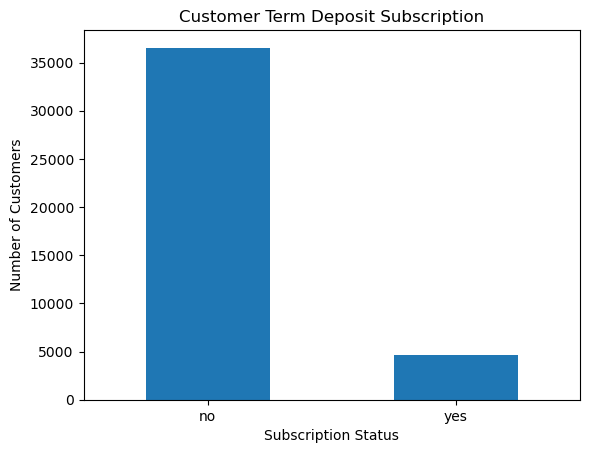

In [9]:
# Count customers in each subscription category
print(df["y"].value_counts())

# Calculate subscription percentage
subscription_rate = (df["y"] == "yes").mean() * 100

print("\nSubscription Rate:", round(subscription_rate, 2), "%")

# Calculate non-subscription percentage
non_subscription_rate = (df["y"] == "no").mean() * 100

print("Non-Subscription Rate:", round(non_subscription_rate, 2), "%")

# Count subscriptions
subscription_counts = df["y"].value_counts()

# Create bar chart
subscription_counts.plot(kind="bar")

plt.title("Customer Term Deposit Subscription")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

## Step 6: Objective 2 — Subscription by Age Group

y             no   yes
age_group             
18-25       1316   349
26-35      13104  1740
36-45      11747  1092
46-55       7530   717
56+         2840   741


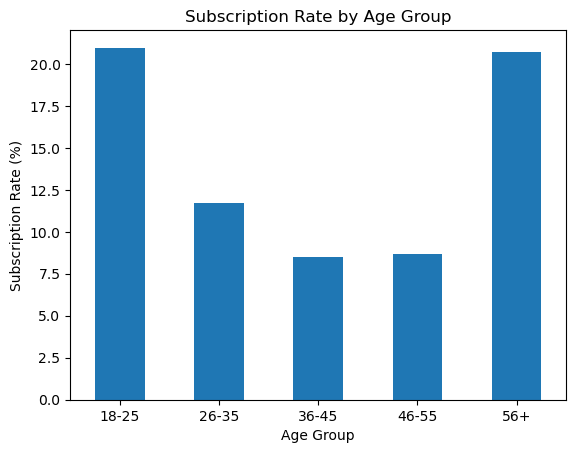

In [10]:
# Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

# Count subscriptions by age group
age_analysis = df.groupby(
    "age_group", observed=False
)["y"].value_counts().unstack(fill_value=0)

print(age_analysis)


# Calculate subscription rate for each age group
age_rate = df.groupby(
    "age_group", observed=False
)["y"].apply(lambda x: (x == "yes").mean() * 100)

# Plot the results
age_rate.plot(kind="bar")

plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.show()

## Step 7: Objective 3 — Call Duration Analysis

Average Call Duration (seconds):
y
no     220.868079
yes    553.256090
Name: duration, dtype: float64


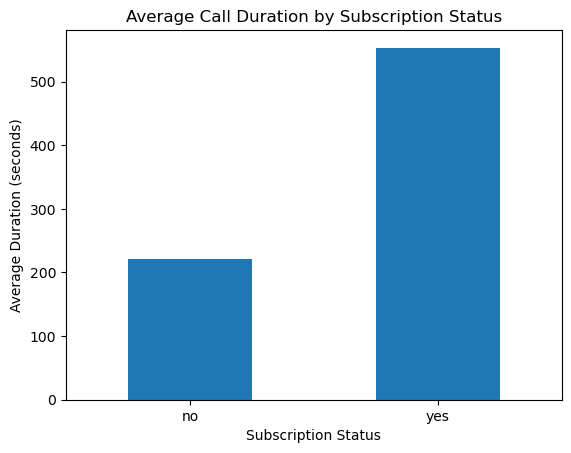

In [11]:
# Calculate average call duration for each subscription group
duration_analysis = df.groupby("y")["duration"].mean()

print("Average Call Duration (seconds):")
print(duration_analysis)

# Visualize average call duration
duration_analysis.plot(kind="bar")

plt.title("Average Call Duration by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Average Duration (seconds)")
plt.xticks(rotation=0)
plt.show()

## Step 8: Objective 4 — Job and Education Analysis

### 8.2 Analyze subscription by job

Subscription Rate by Job:
job
student          31.428571
retired          25.261932
unemployed       14.201183
admin.           12.966695
management       11.217510
unknown          11.212121
technician       10.832468
self-employed    10.485574
housemaid        10.000000
entrepreneur      8.516484
services          8.142173
blue-collar       6.895061
Name: y, dtype: float64


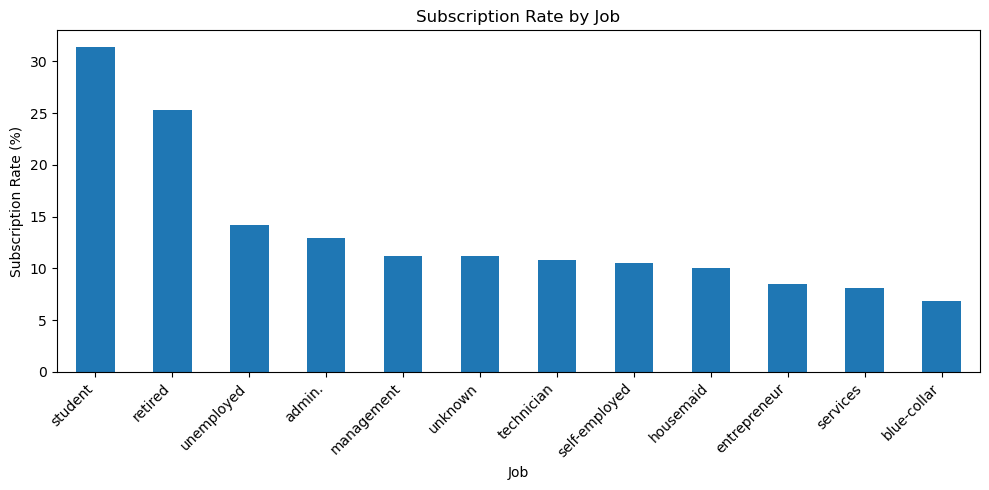

In [12]:
# Calculate subscription rate by job
job_rate = df.groupby("job")["y"].apply(
    lambda x: (x == "yes").mean() * 100
)

job_rate = job_rate.sort_values(ascending=False)

print("Subscription Rate by Job:")
print(job_rate)
job_rate.plot(kind="bar", figsize=(10, 5))

plt.title("Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 8.3 Analyze subscription by education

Subscription Rate by Education:
education
illiterate             22.222222
unknown                14.508671
university.degree      13.720816
professional.course    11.354962
high.school            10.838940
basic.4y               10.249042
basic.6y                8.206024
basic.9y                7.824648
Name: y, dtype: float64


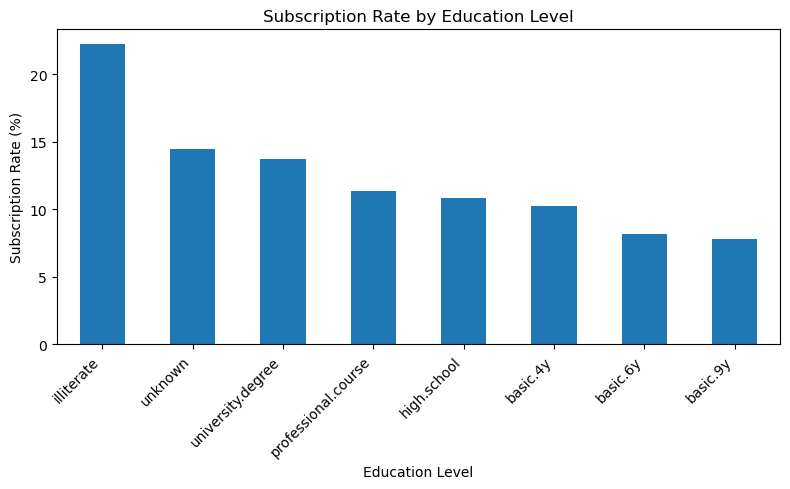

In [13]:
# Calculate subscription rate by education
education_rate = df.groupby("education")["y"].apply(
    lambda x: (x == "yes").mean() * 100
)

education_rate = education_rate.sort_values(ascending=False)

print("Subscription Rate by Education:")
print(education_rate)
education_rate.plot(kind="bar", figsize=(8, 5))

plt.title("Subscription Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Step 9: Objective 5 — Previous Campaign Analysis

Subscription Rate by Previous Campaign Outcome:
poutcome
success        65.112891
failure        14.228598
nonexistent     8.832382
Name: y, dtype: float64


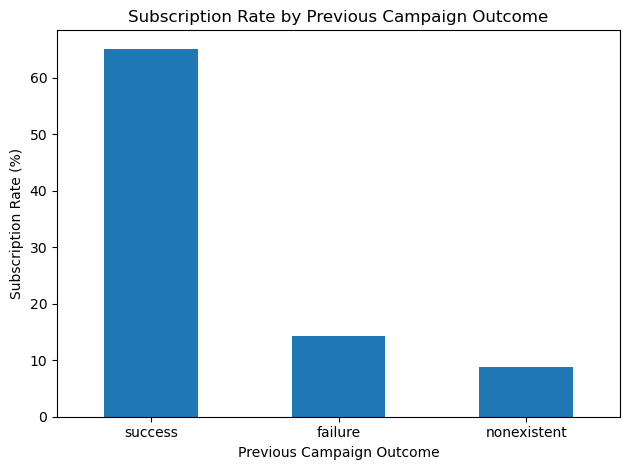

In [15]:
# Calculate subscription rate by previous campaign outcome
previous_rate = df.groupby("poutcome")["y"].apply(
    lambda x: (x == "yes").mean() * 100
)

previous_rate = previous_rate.sort_values(ascending=False)

print("Subscription Rate by Previous Campaign Outcome:")
print(previous_rate)

previous_rate.plot(kind="bar")

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 10: Objective 6 — Subscription by Contact Method

Subscription Rate by Contact Method:
contact
cellular     14.738856
telephone     5.232365
Name: y, dtype: float64


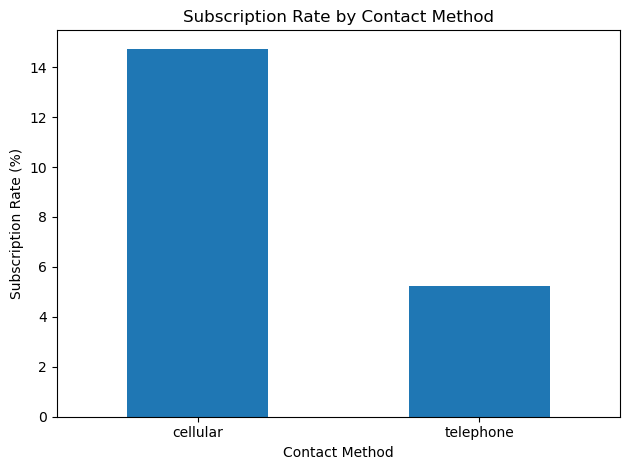

In [16]:
# Calculate subscription rate by contact method
contact_rate = df.groupby("contact")["y"].apply(
    lambda x: (x == "yes").mean() * 100
)

contact_rate = contact_rate.sort_values(ascending=False)

print("Subscription Rate by Contact Method:")
print(contact_rate)
contact_rate.plot(kind="bar")

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 11: Machine Learning Data Preparation

In [17]:
# Copy the dataset for machine learning
ml_df = df.copy()

# Remove columns not suitable for prediction
ml_df = ml_df.drop(columns=["duration", "age_group"])

# Convert target into numbers
ml_df["y"] = ml_df["y"].map({"no": 0, "yes": 1})

# Separate input features and target
X = ml_df.drop("y", axis=1)
y = ml_df["y"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features after encoding:")
print(X.head())

print("\nFinal feature shape:", X.shape)

Input features:
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  campaign  pdays  previous     poutcome  emp.var.rate  \
0   may         mon         1    999         0  nonexistent           1.1   
1   may         mon         1    999         0  nonexistent           1.1   
2   may         mon         1    999         0  nonexistent           1.1   
3   may         mon         1    999         0  nonexistent           1.1   
4   may         mon         1    999         0  nonexistent           1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
0    

## Step 12: Splitting Data into Training and Testing Sets

In [18]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())



Training data: (32940, 52)
Testing data: (8236, 52)

Training target:
y
0    29229
1     3711
Name: count, dtype: int64


## Step 13: Feature Scaling

In [19]:
from sklearn.preprocessing import StandardScaler

# Create scaler
sc = StandardScaler()

# Scale training and testing data
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

print("Training data scaled successfully.")
print("Testing data scaled successfully.")

Training data scaled successfully.
Testing data scaled successfully.


## Step 14: Model 1 — Logistic Regression

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Create the model
lr = LogisticRegression(max_iter=1000)

# Train the model
lr.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lr = lr.predict(X_test_scaled)

print("Logistic Regression Model")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Model
Accuracy: 0.8980087421078193

Confusion Matrix:
[[7202  106]
 [ 734  194]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.94      7308
           1       0.65      0.21      0.32       928

    accuracy                           0.90      8236
   macro avg       0.78      0.60      0.63      8236
weighted avg       0.88      0.90      0.87      8236



## Step 15: Model 2 — K-Nearest Neighbors (KNN)

In [21]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train_scaled, y_train)

# Make predictions
y_pred_knn = knn.predict(X_test_scaled)

# Evaluate the model
print("KNN Model")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Model
Accuracy: 0.8908450704225352

Confusion Matrix:
[[7083  225]
 [ 674  254]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7308
           1       0.53      0.27      0.36       928

    accuracy                           0.89      8236
   macro avg       0.72      0.62      0.65      8236
weighted avg       0.87      0.89      0.88      8236



## Step 16: Model 3 — Decision Tree

In [22]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=8,
    random_state=42
)

# Train the model
dt.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt.predict(X_test)

# Evaluate the model
print("Decision Tree Model")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Model
Accuracy: 0.898251578436134

Confusion Matrix:
[[7146  162]
 [ 676  252]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7308
           1       0.61      0.27      0.38       928

    accuracy                           0.90      8236
   macro avg       0.76      0.62      0.66      8236
weighted avg       0.88      0.90      0.88      8236



## Step 17: Model 4 — Naive Bayes

In [23]:
from sklearn.naive_bayes import GaussianNB

# Create Naive Bayes model
nb = GaussianNB()

# Train the model
nb.fit(X_train_scaled, y_train)

# Make predictions
y_pred_nb = nb.predict(X_test_scaled)

# Evaluate the model
print("Naive Bayes Model")
print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Naive Bayes Model
Accuracy: 0.7344584749878582

Confusion Matrix:
[[5378 1930]
 [ 257  671]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.74      0.83      7308
           1       0.26      0.72      0.38       928

    accuracy                           0.73      8236
   macro avg       0.61      0.73      0.61      8236
weighted avg       0.88      0.73      0.78      8236



## Step 18: Comparison of Machine Learning Models

Machine Learning Model Comparison:
                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.898      0.647   0.209     0.316
1                  KNN     0.891      0.530   0.274     0.361
2        Decision Tree     0.898      0.609   0.272     0.376
3          Naive Bayes     0.734      0.258   0.723     0.380


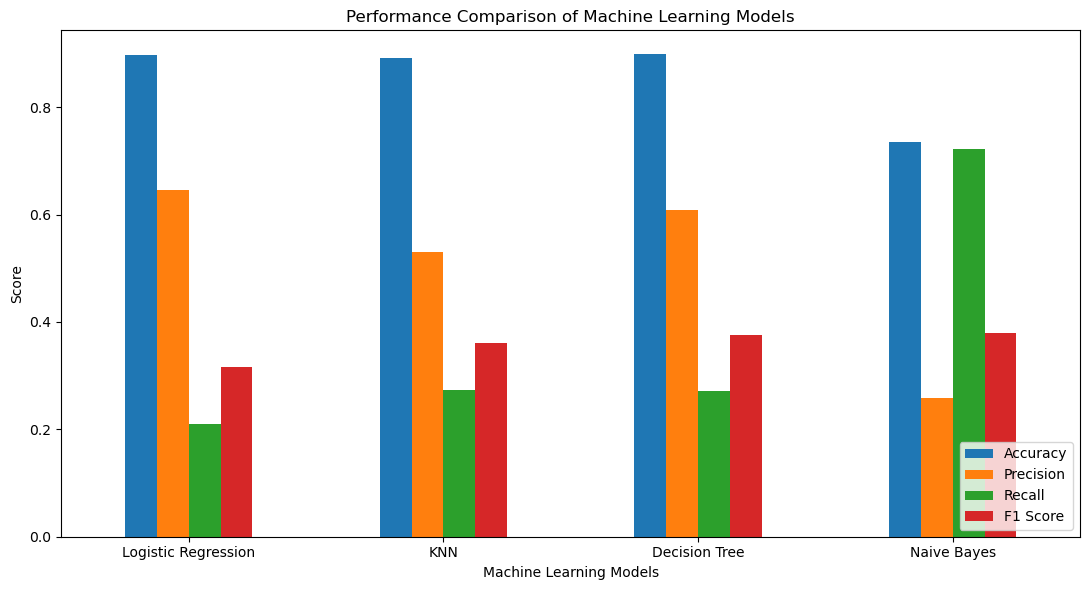

Best Model Based on F1 Score:
Model        Naive Bayes
Accuracy        0.734458
Precision       0.257978
Recall           0.72306
F1 Score        0.380278
Name: 3, dtype: object


In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Store all model predictions
models = {
    "Logistic Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Decision Tree": y_pred_dt,
    "Naive Bayes": y_pred_nb
}

results = []

# Calculate performance metrics
for name, pred in models.items():

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# Create comparison dataframe
results_df = pd.DataFrame(results)

print("Machine Learning Model Comparison:")
print(results_df.round(3))

results_df.set_index("Model")[[
    "Accuracy", "Precision", "Recall", "F1 Score"
]].plot(kind="bar", figsize=(11, 6))

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("Best Model Based on F1 Score:")
print(best_model)

## Step 20: Best Model Performance Analysis

Naive Bayes Confusion Matrix:
[[5378 1930]
 [ 257  671]]


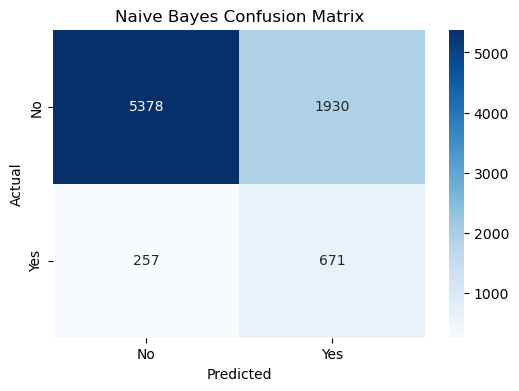

In [27]:
# Confusion matrix of best model
cm = confusion_matrix(y_test, y_pred_nb)

print("Naive Bayes Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Step 21: Feature Importance Analysis

Top 10 Important Features:
                 Feature  Importance
8            nr.employed    0.575009
6          cons.conf.idx    0.088330
2                  pdays    0.079901
7              euribor3m    0.058727
0                    age    0.035877
1               campaign    0.028191
5         cons.price.idx    0.027804
44             month_oct    0.018533
50  poutcome_nonexistent    0.010505
36     contact_telephone    0.009144


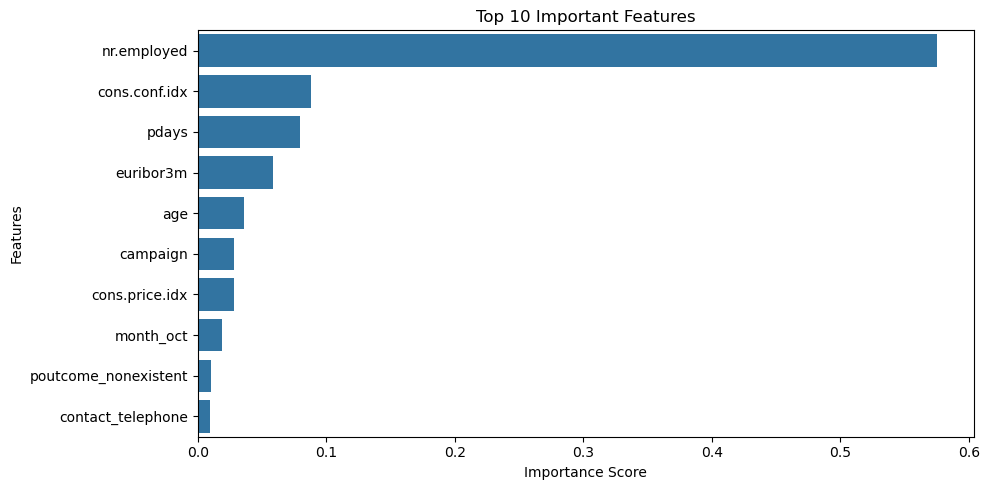

In [29]:
# Get feature importance from Decision Tree
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
print(importance.head(10))

# Plot top 10 important features
top_features = importance.head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()